In [39]:
import pandas as pd
import sys
import os

# add parent directory to import path
current = os.getcwd()
parent = os.path.dirname(current)
sys.path.append(parent)


df = pd.read_csv(parent+"/data/raw/train_FD001.txt", delim_whitespace=True, names=["unit number", "time, in cycles","operational setting 1","operational setting 2","operational setting 3","sensor measurement  1",
                                                                                            "sensor measurement  2","sensor measurement  3", "sensor measurement  4","sensor measurement  5",
                                                                                            "sensor measurement  6","sensor measurement  7","sensor measurement  8","sensor measurement  9",
                                                                                            "sensor measurement  10","sensor measurement  11", "sensor measurement  12","sensor measurement  13",
                                                                                            "sensor measurement  14","sensor measurement  15", "sensor measurement  16","sensor measurement  17",
                                                                                            "sensor measurement  18","sensor measurement  19", "sensor measurement  20","sensor measurement  21"])
df.head()

C:\Users\wasse\AppData\Local\Temp\ipykernel_29140\2934761009.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(parent+"/data/raw/train_FD001.txt", delim_whitespace=True, names=["unit number", "time, in cycles","operational setting 1","operational setting 2","operational setting 3","sensor measurement  1",


,unit number,"time, in cycles",operational setting 1,operational setting 2,operational setting 3,sensor measurement 1,sensor measurement 2,sensor measurement 3,sensor measurement 4,sensor measurement 5,...,sensor measurement 12,sensor measurement 13,sensor measurement 14,sensor measurement 15,sensor measurement 16,sensor measurement 17,sensor measurement 18,sensor measurement 19,sensor measurement 20,sensor measurement 21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   unit number             20631 non-null  int64  
 1   time, in cycles         20631 non-null  int64  
 2   operational setting 1   20631 non-null  float64
 3   operational setting 2   20631 non-null  float64
 4   operational setting 3   20631 non-null  float64
 5   sensor measurement  1   20631 non-null  float64
 6   sensor measurement  2   20631 non-null  float64
 7   sensor measurement  3   20631 non-null  float64
 8   sensor measurement  4   20631 non-null  float64
 9   sensor measurement  5   20631 non-null  float64
 10  sensor measurement  6   20631 non-null  float64
 11  sensor measurement  7   20631 non-null  float64
 12  sensor measurement  8   20631 non-null  float64
 13  sensor measurement  9   20631 non-null  float64
 14  sensor measurement  10  20631 non-null

In [40]:
df["RUL"] = df.groupby("unit number")["time, in cycles"].transform("max") - df["time, in cycles"]
df["RUL"] = df["RUL"].clip(upper=125)

In [4]:

max_cycle = df.groupby("unit number").max("RUL")["RUL"]
#plt.hist(df["RUL"])
max_cycle

unit number
1      125
2      125
3      125
4      125
5      125
      ... 
96     125
97     125
98     125
99     125
100    125
Name: RUL, Length: 100, dtype: int64

Index(['operational setting 3', 'sensor measurement  1',
       'sensor measurement  5', 'sensor measurement  10',
       'sensor measurement  16', 'sensor measurement  18',
       'sensor measurement  19'],
      dtype='object')


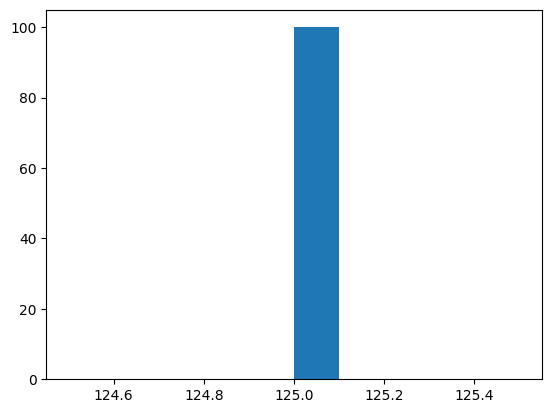

In [5]:
import matplotlib.pyplot as plt
max_cycle = df.groupby("unit number").max("RUL")["RUL"]
plt.hist(max_cycle)

constant_cols = df.columns[df.nunique() == 1]
print(constant_cols)

c:\Users\wasse\miniconda3\envs\RUL\lib\site-packages\numpy\lib\_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\wasse\miniconda3\envs\RUL\lib\site-packages\numpy\lib\_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


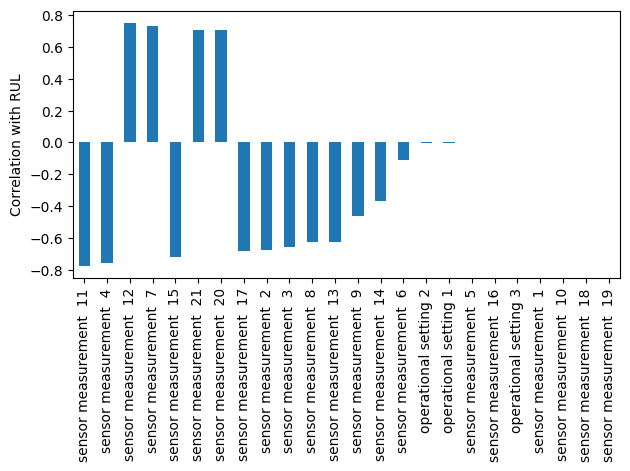

In [8]:
sensor_cols = df.select_dtypes(include="number").columns.drop(
    ["unit number", "time, in cycles", "RUL"]
)

corr = df[sensor_cols].corrwith(df["RUL"])

# sort by absolute strength
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)

# plot
corr.plot(kind="bar")
plt.ylabel("Correlation with RUL")
plt.tight_layout()
plt.show()

In [24]:
plot_data[50:]

,sensor measurement 11,sensor measurement 4,sensor measurement 12,sensor measurement 7,sensor measurement 15
50,47.12,1400.42,521.91,553.73,8.4504
51,47.07,1395.57,522.10,553.04,8.4539
52,47.29,1402.26,521.96,554.16,8.4418
53,47.38,1401.20,522.44,553.95,8.4189
54,47.40,1401.58,522.11,554.45,8.4071
...,...,...,...,...,...
187,48.00,1422.78,519.79,551.94,8.5207
188,48.08,1428.01,519.58,550.70,8.5183
189,48.33,1425.95,520.04,551.29,8.5223
190,48.15,1425.77,519.57,550.92,8.5174


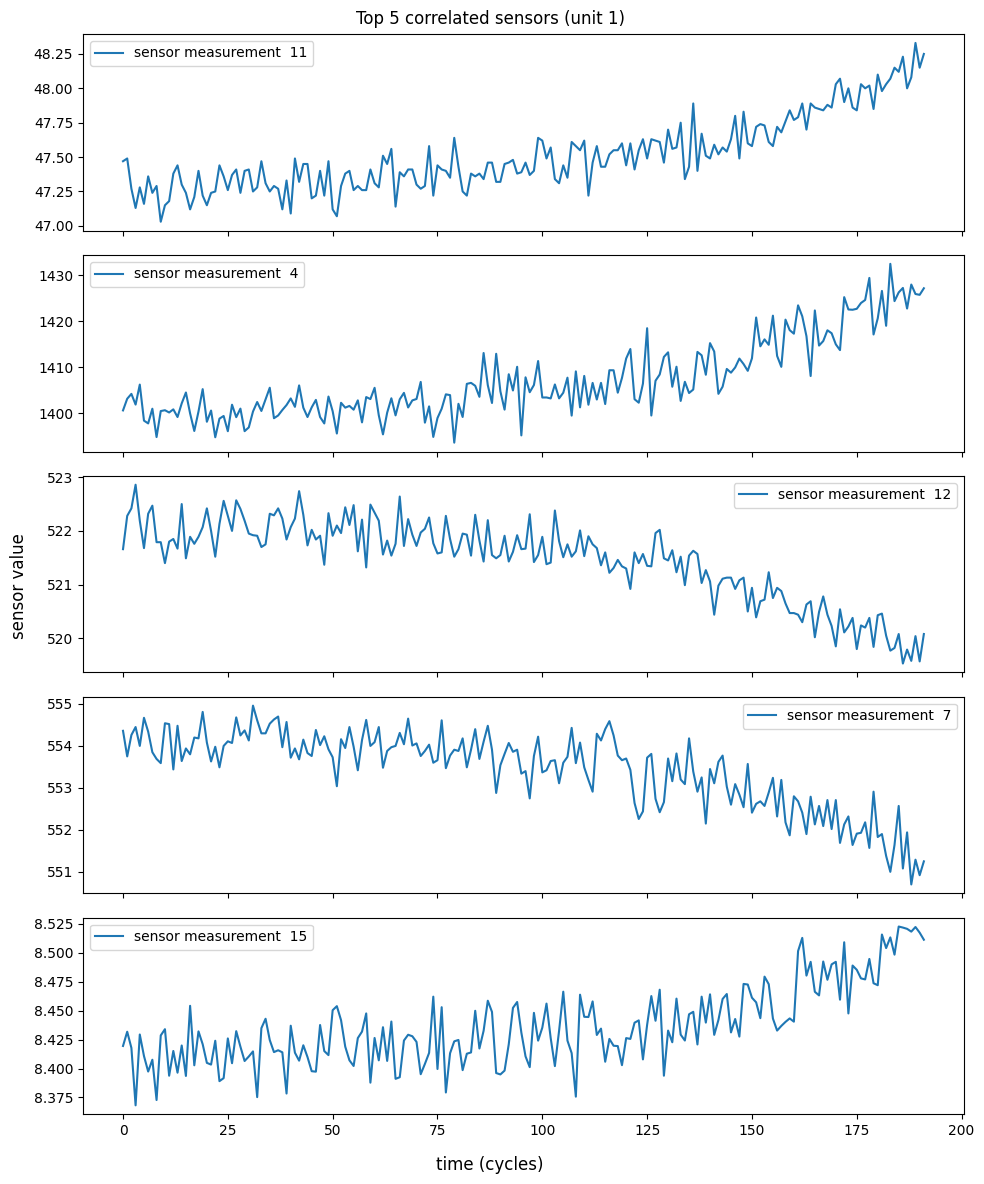

In [22]:
top5 = corr.keys()[:5]


plot_data = df[df["unit number"]==1][top5]

fig, ax = plt.subplots(5, 1, figsize=(10, 12), sharex=True)

for i,col in enumerate(plot_data.columns):
    ax[i].plot(plot_data.index, plot_data[col], label=col)
    ax[i].legend()

fig.supxlabel("time (cycles)")
fig.supylabel("sensor value")
fig.suptitle("Top 5 correlated sensors (unit 1)")
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Total engine lifetime (cycles)')

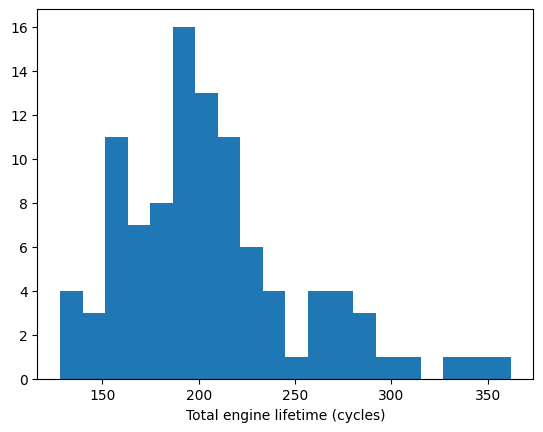

In [15]:
max_cycles_raw = df.groupby("unit number")["time, in cycles"].max()
plt.hist(max_cycles_raw, bins=20)
plt.xlabel("Total engine lifetime (cycles)")


In [44]:
def compute_features(df: pd.DataFrame, window: int = 30) -> pd.DataFrame:
    """
    Given raw CMAPSS dataframe (with RUL column), returns a dataframe
    with rolling and difference features added.
    Drops rows with NaN values introduced by rolling windows.
    """
    df = df.copy()

    base_drop = [
        "unit number",
        "time, in cycles",
        "operational setting 1",
        "operational setting 2",
        "operational setting 3",
        "RUL"
    ]

    sensor_cols = df.select_dtypes(include="number").columns.drop(base_drop)

    # remove low variance once, before feature generation
    low_var = df[sensor_cols].std()
    sensor_cols = low_var[low_var >= 0.01].index
    df = df.drop(columns=low_var[low_var < 0.01].index)

    # recompute AFTER dropping
    sensor_cols = df.select_dtypes(include="number").columns.drop(base_drop)

    grouped = df.groupby("unit number")

    new_cols = []

    for col in sensor_cols:
        df[f"{col}_mean"] = grouped[col].rolling(window).mean().reset_index(level=0, drop=True)
        df[f"{col}_std"]  = grouped[col].rolling(window).std().reset_index(level=0, drop=True)
        df[f"{col}_diff"] = grouped[col].diff()

        new_cols += [f"{col}_mean", f"{col}_std", f"{col}_diff"]

    # ONLY drop rows where new features are incomplete
    df = df.dropna(subset=new_cols)
    df = df.drop(columns=sensor_cols)


    return df

In [45]:
df_smoothed = compute_features(df,30)
df_smoothed

,unit number,"time, in cycles",operational setting 1,operational setting 2,operational setting 3,RUL,sensor measurement 2_mean,sensor measurement 2_std,sensor measurement 2_diff,sensor measurement 3_mean,...,sensor measurement 15_diff,sensor measurement 17_mean,sensor measurement 17_std,sensor measurement 17_diff,sensor measurement 20_mean,sensor measurement 20_std,sensor measurement 20_diff,sensor measurement 21_mean,sensor measurement 21_std,sensor measurement 21_diff
29,1,30,-0.0022,0.0000,100.0,125,642.328333,0.328498,0.29,1587.558333,...,-0.0124,391.933333,0.980265,-3.0,38.972667,0.084443,0.12,23.385460,0.052695,0.0513
30,1,31,0.0014,0.0005,100.0,125,642.335000,0.319739,-0.18,1587.374333,...,0.0039,391.933333,0.980265,2.0,38.968667,0.082993,-0.11,23.382670,0.053073,-0.0757
31,1,32,0.0005,-0.0003,100.0,125,642.341000,0.317830,0.31,1587.359667,...,0.0044,391.933333,0.980265,0.0,38.969333,0.083333,0.08,23.385213,0.056799,0.1646
32,1,33,-0.0042,-0.0004,100.0,125,642.353000,0.324899,0.38,1587.373333,...,-0.0395,392.000000,0.909718,0.0,38.965333,0.087088,-0.19,23.385427,0.056652,-0.1493
33,1,34,0.0015,-0.0001,100.0,125,642.359333,0.326686,-0.17,1587.329333,...,0.0596,392.000000,0.909718,0.0,38.963000,0.090331,-0.02,23.383270,0.058313,-0.0414
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,4,643.297667,0.321502,0.08,1598.128667,...,-0.0563,395.366667,1.159171,3.0,38.529667,0.136899,0.35,23.138527,0.073789,-0.2188
20627,100,197,-0.0016,-0.0005,100.0,3,643.296667,0.320671,0.05,1598.383333,...,0.0183,395.333333,1.154701,-2.0,38.519333,0.142222,-0.19,23.136257,0.071983,0.1859
20628,100,198,0.0004,0.0000,100.0,2,643.311667,0.315344,-0.12,1598.684667,...,0.0507,395.433333,1.250747,3.0,38.513667,0.141871,0.14,23.125283,0.076992,-0.2261
20629,100,199,-0.0011,0.0003,100.0,1,643.324333,0.303573,-0.19,1599.079333,...,-0.0257,395.433333,1.250747,-3.0,38.499667,0.142550,-0.15,23.120213,0.075805,0.1307


In [50]:
fe = FeatureEngineer()
fe.fit(df)
fe.save("artifacts/feature_engineer.joblib")


